# AVAX SHORT — thuận xu hướng: Bollinger dài hạn + RSI ngắn hạn, **nhiều lệnh chồng nhau**, train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục (logic chung ở `reference/multi_position/multi_position_engine.py`, luật breakout `entry_mode = 0`). Sửa **ô Cấu hình**, rồi chọn **Run All**. Kết quả lưu thành CSV cạnh notebook.

**Vào lệnh ở close của nến `i`:** `close[i-1] > lower[i] > close[i]` (đóng cửa vượt xuống dưới dải dưới) **và** `RSI[i] < rsi_threshold`.

**Rủi ro:** risk = `sl_multiplier × (upper[i] − entry)`; stop = entry + risk; TP = entry − `tp_sl_ratio` × risk; `tp_sl_ratio = 0` là **không chốt lời**. Timeout `MAX_HOLDING_BARS` nến; phí vào lệnh `0.001 / sl_ratio` (bỏ lệnh nếu > 0.2R); phí giữ lệnh mỗi 8 giờ (`FEE_BARS = None` ⇒ 96 ở 5min).

**Khác bản gốc `reference/short_bollinger+RSI+trend`:** bản gốc giữ **một lệnh** và bỏ mọi tín hiệu xuất hiện khi lệnh đang mở (cột `skipped_entries`). Ở đây **mỗi tín hiệu mở một lệnh riêng**, có stop/TP/timeout riêng và đóng độc lập. Tại mỗi nến: (1) xét tín hiệu, (2) xét thoát cho các lệnh đang mở (timeout → stop → TP → hết dữ liệu), (3) thêm lệnh mới (bắt đầu xét thoát từ nến sau). `MAX_OPEN` giới hạn số lệnh mở cùng lúc (tối đa 64); **`MAX_OPEN = 1` cho kết quả trùng tuyệt đối bản gốc**. Với `MAX_OPEN = 64`, `skipped_entries` chỉ khác 0 khi có hơn 64 lệnh mở cùng lúc.

**Đọc kết quả:** R tính **cho mỗi lệnh**. Khi N lệnh mở cùng lúc, rủi ro thực là N·R, nên R/tháng của bản nhiều lệnh không so thẳng được với bản 1 lệnh. Xem thêm `mtm_max_dd` (drawdown khi định giá cả lệnh đang mở theo close mỗi nến), `max_concurrent` / `avg_concurrent` (số lệnh mở tối đa / trung bình mỗi nến). Ô so sánh đặt cạnh `r_per_month / max_concurrent` — lợi nhuận nếu chia vốn rủi ro cho số lệnh tối đa.

Grid search trên toàn khoảng train là **in-sample**; đánh giá ngoài mẫu bằng `reference/walk_forward_multi_asset.py --folder multi_position/short_bollinger+RSI+trend` (đọc grid và `SCORE_FORMULA` từ ô Cấu hình này).

In [1]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                 # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2024-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-07-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = reference/data_5m/avaxusdt_futures_5min.csv
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

#SCORE_FORMULA = "r_martin_monthly"
#SCORE_FORMULA = "r_sharpe_monthly"
SCORE_FORMULA = "performance/number_of_trade*r2**5"
# Sửa trực tiếp các danh sách dưới đây để đổi grid. Số bộ tham số là tích số giá trị mỗi danh sách.
# tp_sl_ratio = 0 nghĩa là không chốt lời (chỉ stop hoặc hết thời gian giữ).
SEARCH_SPACES = {
    "boll_window": [40, 45, 50, 60, 80, 100, 150, 200, 400],
    "boll_window_dev": [1.8, 2.0, 2.2, 2.5],
    "rsi_window": [5, 7, 9, 14, 20, 30],
    "rsi_threshold": [5, 10, 15, 20, 25, 30, 35, 40],
    "sl_multiplier": [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 100             # số nến tối đa giữ lệnh theo TIMEFRAME
MAX_OPEN = 5                       # số lệnh mở cùng lúc tối đa (1 = bản gốc một lệnh; tối đa 64)
FEE_BARS = None                    # None = 8 giờ mỗi lần phí (96 ở 5min)
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 100                     # bảng xếp hạng chỉ giữ bộ có ít nhất số lệnh này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [2]:
# Nạp script cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+RSI+trend"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER and parent.parent.name == "multi_position":
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / "multi_position" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

spec = importlib.util.spec_from_file_location("avax_multi_short_bollinger_RSI_trend", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
if not 1 <= MAX_OPEN <= strategy.MAX_SLOTS:
    raise ValueError(f"MAX_OPEN phải trong khoảng 1..{strategy.MAX_SLOTS}")
print("CSV:", csv_path)
print("Đã nạp:", script_path)
print("Phí giữ lệnh: mỗi", strategy.resolve_fee_bars(TIMEFRAME, FEE_BARS), "nến; MAX_OPEN =", MAX_OPEN)

CSV: C:\Users\Legion\Desktop\TradingProject\reference\data_5m\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\short_bollinger+RSI+trend\train_full_grid_gpu.py
Phí giữ lệnh: mỗi 32.0 nến; MAX_OPEN = 5


In [3]:
# Đọc dữ liệu, resample và tạo grid
strategy.timeframe_nanos(TIMEFRAME)
start_date, end_date = START_DATE, END_DATE
expected_keys = set(strategy.SEARCH_SPACE)
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 52,608 nến; 2024-01-01 00:00:00 → 2025-07-01 23:45:00
Grid: 19,008 bộ tham số


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio
0,40,1.8,5,5,0.5,1.1
1,40,1.8,5,5,0.6,1.1
2,40,1.8,5,5,0.7,1.1
3,40,1.8,5,5,0.8,1.1
4,40,1.8,5,5,0.9,1.1


In [4]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
    max_open=MAX_OPEN,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")
print(f"Lệnh mở cùng lúc: tối đa {result['max_concurrent'].max()}, trung vị của max {result['max_concurrent'].median():g}; "
      f"tín hiệu bị bỏ vì đủ MAX_OPEN: {int(result['skipped_entries'].sum()):,}")

c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 0.987768999999389, 'holding_fee_bars': 32.0, 'total_gpu_s': 3.6838563000783324}
Đã tính 19,008 bộ tham số
Lệnh mở cùng lúc: tối đa 5, trung vị của max 4; tín hiệu bị bỏ vì đủ MAX_OPEN: 478,023


In [5]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = strategy.score_result(result, SCORE_FORMULA)
print("Score:", SCORE_FORMULA)

Score: performance/number_of_trade*r2**5


In [6]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với replay float64
# Có thể lệch rất ít bộ khi giá chạm dải/stop sát ngưỡng làm tròn fp32.
if VERIFY_SAMPLES:
    strategy.verify_samples(bars, result, VERIFY_SAMPLES, MAX_HOLDING_BARS, FEE_BARS, TIMEFRAME, MAX_OPEN)

In [7]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_{TIMEFRAME}_fp32.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] >= MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và ≥ {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\multi_position\short_bollinger+RSI+trend\full_gpu_grid_results_15min_fp32.csv
Bộ có score hợp lệ và ≥ 100 lệnh: 9,515/19,008


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
17413,400,1.8,30,40,0.5,1.1,57.122326,9.40,2.15,0.930064,...,3.456389,0.917933,0.683445,13.574944,0.277296,204,5,7,0.194868,performance/number_of_trade*r2**5
13708,150,2.0,30,35,0.7,1.1,34.063271,3.72,0.77,0.933175,...,1.691882,1.118263,0.680351,4.948338,0.184782,127,5,5,0.189801,performance/number_of_trade*r2**5
13707,150,2.0,30,35,0.6,1.1,32.967621,3.86,0.98,0.926619,...,1.800258,1.017140,0.596589,5.622171,0.173377,129,5,3,0.174584,performance/number_of_trade*r2**5
17314,400,1.8,20,35,0.5,1.1,38.609241,9.81,2.16,0.888181,...,3.244247,0.661006,0.650484,11.077180,0.189325,137,4,0,0.155768,performance/number_of_trade*r2**5
13706,150,2.0,30,35,0.5,1.1,32.442257,6.12,1.28,0.898797,...,2.549739,0.706713,0.517725,6.927790,0.155395,130,5,2,0.146378,performance/number_of_trade*r2**5
17941,400,2.0,30,40,0.5,1.1,39.735897,5.77,1.33,0.933149,...,2.131401,1.035489,0.528589,8.434765,0.311683,213,5,10,0.131995,performance/number_of_trade*r2**5
17215,400,1.8,14,30,0.5,1.1,23.509342,6.97,1.65,0.890256,...,2.427776,0.537848,0.498069,8.686377,0.138876,101,3,0,0.130165,performance/number_of_trade*r2**5
13709,150,2.0,30,35,0.8,1.1,26.842567,3.62,0.77,0.902682,...,1.577189,0.945296,0.613510,4.692911,0.199152,127,5,5,0.126676,performance/number_of_trade*r2**5
2624,45,1.8,30,35,1.1,1.1,37.424946,4.75,1.37,0.912213,...,2.221268,0.935811,0.551498,7.250950,0.302768,192,5,6,0.123123,performance/number_of_trade*r2**5
17414,400,1.8,30,40,0.6,1.1,45.726673,9.27,2.40,0.886796,...,3.483126,0.729169,0.619158,12.655220,0.311778,204,5,7,0.122930,performance/number_of_trade*r2**5


In [8]:
# So với bản MỘT lệnh (MAX_OPEN = 1 = bản gốc short_bollinger+RSI+trend) trên cùng grid, cùng dữ liệu, cùng phí
one, _ = strategy.run_gpu_grid(bars, grid, TIMEFRAME, max_holding_bars=MAX_HOLDING_BARS,
                               fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=1)


def summary(frame):
    ok = frame["number_of_trade"] >= MIN_TRADES
    f = frame[ok]
    return pd.Series({
        "số bộ ≥ MIN_TRADES": int(ok.sum()),
        "số lệnh (trung vị)": f["number_of_trade"].median(),
        "tín hiệu bị bỏ (trung vị)": f["skipped_entries"].median(),
        "R/tháng (trung vị)": f["r_per_month"].median(),
        "% bộ có lãi": (f["performance"] > 0).mean(),
        "max DD đã chốt (trung vị, R)": f["max_dd"].median(),
        "max DD MTM (trung vị, R)": f["mtm_max_dd"].median(),
        "Martin (trung vị)": f["r_martin_monthly"].median(),
        "lệnh mở tối đa (trung vị)": f["max_concurrent"].median(),
        "lệnh mở trung bình (trung vị)": f["avg_concurrent"].median(),
        "R/tháng ÷ lệnh mở tối đa (trung vị)": (f["r_per_month"] / f["max_concurrent"].clip(lower=1)).median(),
        "R/tháng ÷ max DD MTM (trung vị)": (f["r_per_month"] / f["mtm_max_dd"]).median(),
    })


comparison = pd.DataFrame({"1 lệnh (gốc)": summary(one), f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": summary(result)})
display(comparison.round(3))
both = (one["number_of_trade"] >= MIN_TRADES) & (result["number_of_trade"] >= MIN_TRADES)
print(f"Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở {(result.loc[both, 'r_per_month'] > one.loc[both, 'r_per_month']).mean():.1%} bộ; "
      f"Martin cao hơn ở {(result.loc[both, 'r_martin_monthly'] > one.loc[both, 'r_martin_monthly']).mean():.1%} bộ")
print(f"Tương quan hạng score giữa hai bản: {result.loc[both, 'score'].corr(one.loc[both, 'score'], method='spearman'):.3f}")

,1 lệnh (gốc),nhiều lệnh (MAX_OPEN=5)
số bộ ≥ MIN_TRADES,8093.000,9515.000
số lệnh (trung vị),240.000,498.000
tín hiệu bị bỏ (trung vị),387.000,20.000
R/tháng (trung vị),0.691,1.179
% bộ có lãi,0.956,0.931
"max DD đã chốt (trung vị, R)",9.050,18.860
"max DD MTM (trung vị, R)",9.670,20.440
Martin (trung vị),0.208,0.161
lệnh mở tối đa (trung vị),1.000,5.000
lệnh mở trung bình (trung vị),0.299,0.666


Cùng bộ tham số: nhiều lệnh có R/tháng cao hơn ở 79.3% bộ; Martin cao hơn ở 36.5% bộ
Tương quan hạng score giữa hai bản: 0.513


In [9]:
# So sánh theo từng chiều tham số: trung vị toàn grid (ít nhiễu hơn bộ "tốt nhất")
view = result.assign(tp_kind=np.where(result["tp_sl_ratio"] > 0, "R cố định", "không TP"))


def family(frame):
    return pd.Series({
        "số bộ": len(frame),
        "lệnh (trung vị)": frame["number_of_trade"].median(),
        f"% bộ ≥ {MIN_TRADES} lệnh": (frame["number_of_trade"] >= MIN_TRADES).mean(),
        "R/tháng (trung vị)": frame["r_per_month"].median(),
        "% bộ có lãi": (frame["performance"] > 0).mean(),
        "max DD MTM (trung vị)": frame["mtm_max_dd"].median(),
        "lệnh mở tối đa (trung vị)": frame["max_concurrent"].median(),
    })


for columns in (["tp_sl_ratio"], ["rsi_window"], ["boll_window"], ["rsi_threshold"], ["sl_multiplier"]):
    print("Theo", ", ".join(columns))
    display(view.groupby(columns)[list(view.columns)].apply(family).round(3))

Theo tp_sl_ratio


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD MTM (trung vị),lệnh mở tối đa (trung vị)
tp_sl_ratio,,,,,,,
1.1,19008.0,100.5,0.501,0.2,0.701,6.739,4.0


Theo rsi_window


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD MTM (trung vị),lệnh mở tối đa (trung vị)
rsi_window,,,,,,,
5,3168.0,403.5,0.785,0.817,0.843,17.241,5.0
7,3168.0,272.0,0.660,0.573,0.811,12.350,5.0
9,3168.0,179.0,0.583,0.318,0.756,9.306,5.0
14,3168.0,46.0,0.427,0.088,0.686,3.780,3.0
20,3168.0,11.0,0.326,0.033,0.603,1.580,2.0
30,3168.0,3.0,0.222,0.007,0.509,0.645,1.0


Theo boll_window


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD MTM (trung vị),lệnh mở tối đa (trung vị)
boll_window,,,,,,,
40,2112.0,192.5,0.557,0.197,0.725,11.413,5.0
45,2112.0,170.0,0.547,0.304,0.764,9.753,5.0
50,2112.0,153.5,0.547,0.334,0.795,9.957,5.0
60,2112.0,141.0,0.542,0.391,0.802,9.073,5.0
80,2112.0,109.5,0.510,0.177,0.656,7.707,4.0
100,2112.0,93.5,0.490,0.221,0.659,6.482,4.0
150,2112.0,77.0,0.464,0.160,0.594,5.633,4.0
200,2112.0,63.0,0.453,0.109,0.612,4.658,3.0
400,2112.0,48.0,0.396,0.149,0.705,2.875,3.0


Theo rsi_threshold


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD MTM (trung vị),lệnh mở tối đa (trung vị)
rsi_threshold,,,,,,,
5,2376.0,0.0,0.000,0.000,0.226,0.000,0.0
10,2376.0,4.0,0.065,0.000,0.395,0.822,1.0
15,2376.0,18.0,0.218,0.038,0.670,2.110,2.0
20,2376.0,53.0,0.421,0.113,0.775,4.176,3.0
25,2376.0,147.0,0.569,0.275,0.737,9.143,5.0
30,2376.0,322.0,0.769,0.731,0.930,14.059,5.0
35,2376.0,555.0,0.963,1.338,0.948,22.415,5.0
40,2376.0,762.5,1.000,1.506,0.929,33.819,5.0


Theo sl_multiplier


,số bộ,lệnh (trung vị),% bộ ≥ 100 lệnh,R/tháng (trung vị),% bộ có lãi,max DD MTM (trung vị),lệnh mở tối đa (trung vị)
sl_multiplier,,,,,,,
0.5,1728.0,100.5,0.501,0.060,0.573,9.963,4.0
0.6,1728.0,100.5,0.501,0.175,0.669,8.946,4.0
0.7,1728.0,100.5,0.501,0.195,0.700,8.227,4.0
0.8,1728.0,100.5,0.501,0.200,0.705,7.694,4.0
0.9,1728.0,100.5,0.501,0.256,0.724,7.116,4.0
1.0,1728.0,100.5,0.501,0.332,0.741,6.583,4.0
1.1,1728.0,100.5,0.501,0.303,0.729,6.132,4.0
1.2,1728.0,100.5,0.501,0.254,0.723,5.816,4.0
1.3,1728.0,100.5,0.501,0.226,0.722,5.478,4.0


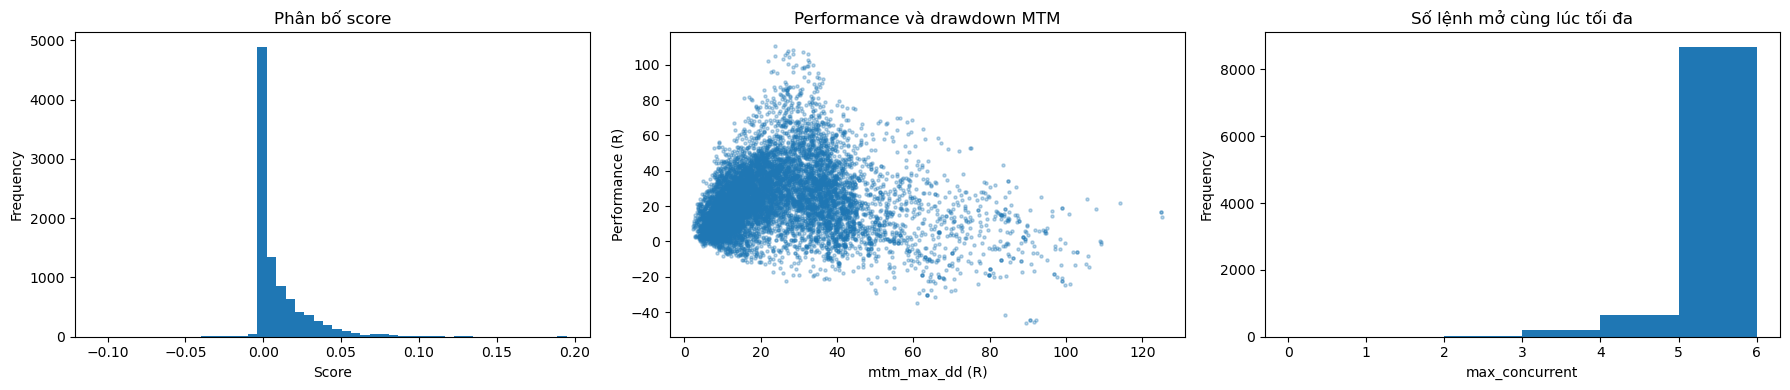

In [10]:
# Biểu đồ: phân bố score, hiệu quả theo drawdown MTM, và số lệnh mở cùng lúc
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    axes[1].scatter(ranked["mtm_max_dd"], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel="mtm_max_dd (R)", ylabel="Performance (R)", title="Performance và drawdown MTM")
    ranked["max_concurrent"].plot.hist(ax=axes[2], bins=range(0, int(ranked["max_concurrent"].max()) + 2),
                                       title="Số lệnh mở cùng lúc tối đa")
    axes[2].set_xlabel("max_concurrent")
    plt.tight_layout()
    plt.show()

c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Giai đoạn backtest: 2024-01-01 00:00:00 đến 2026-10-14 23:45:00
Tham số: {'boll_window': 400.0, 'boll_window_dev': 1.8, 'rsi_window': 30.0, 'rsi_threshold': 40.0, 'sl_multiplier': 0.5, 'tp_sl_ratio': 1.1}


,boll_window,boll_window_dev,rsi_window,rsi_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,...,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,avg_concurrent,number_of_trade,max_concurrent,skipped_entries,score,score_formula
backtest_trial,400,1.8,30,40,0.5,1.1,36.208363,20.42,4.56,0.744379,...,7.033337,0.153923,0.231595,21.884426,0.279132,394,5,13,0.021003,performance/number_of_trade*r2**5


,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,mtm_max_dd,max_concurrent,avg_concurrent,skipped_entries
nhiều lệnh (MAX_OPEN=5),36.208391,20.42,4.56,0.744379,394.0,1.082595,7.033330,0.153924,0.231595,21.884397,5.0,0.279132,13.0
1 lệnh (gốc),3.567862,13.00,3.17,0.624055,191.0,0.106676,4.360731,0.024463,0.052618,14.004517,1.0,0.135908,216.0


,số lệnh
outcome,
timeout,165
take_profit,133
stop,94
end_of_data,2


,entry_index,entry_timestamp,exit_index,close_timestamp,entry_price,risk,stop_loss,take_profit,tp_r,holding_bars,open_at_entry,outcome,gross_r,entry_fee,holding_fee,net_r
0,503,2024-01-06 05:45:00,603,2024-01-07 06:45:00,34.135,4.292260,38.427260,29.413514,1.1,100,1,timeout,-0.301240,0.007953,0.002485,-0.311678
1,669,2024-01-07 23:15:00,745,2024-01-08 18:15:00,33.125,2.686018,35.811018,30.170380,1.1,76,2,stop,-1.000000,0.012332,0.002929,-1.015261
2,675,2024-01-08 00:45:00,745,2024-01-08 18:15:00,33.206,2.650718,35.856718,30.290210,1.1,70,4,stop,-1.000000,0.012527,0.002740,-1.015267
3,678,2024-01-08 01:30:00,745,2024-01-08 18:15:00,33.130,2.687118,35.817118,30.174171,1.1,67,5,stop,-1.000000,0.012329,0.002581,-1.014911
4,667,2024-01-07 22:45:00,746,2024-01-08 18:30:00,33.432,2.528541,35.960541,30.650605,1.1,79,1,stop,-1.000000,0.013222,0.003264,-1.016486
5,672,2024-01-08 00:00:00,746,2024-01-08 18:30:00,33.501,2.503140,36.004140,30.747546,1.1,74,3,stop,-1.000000,0.013384,0.003095,-1.016479
6,1498,2024-01-16 14:30:00,1526,2024-01-16 21:30:00,34.784,1.349488,36.133488,33.299563,1.1,28,1,stop,-1.000000,0.025776,0.002255,-1.028031
7,1675,2024-01-18 10:45:00,1699,2024-01-18 16:45:00,35.133,0.822593,35.955593,34.228147,1.1,24,1,take_profit,1.100000,0.042710,0.003203,1.054087
8,1680,2024-01-18 12:00:00,1699,2024-01-18 16:45:00,35.060,0.858930,35.918930,34.115177,1.1,19,2,take_profit,1.100000,0.040818,0.002424,1.056758
9,1863,2024-01-20 09:45:00,1963,2024-01-21 10:45:00,32.066,2.565578,34.631578,29.243864,1.1,100,1,timeout,-0.515283,0.012499,0.003906,-0.531688


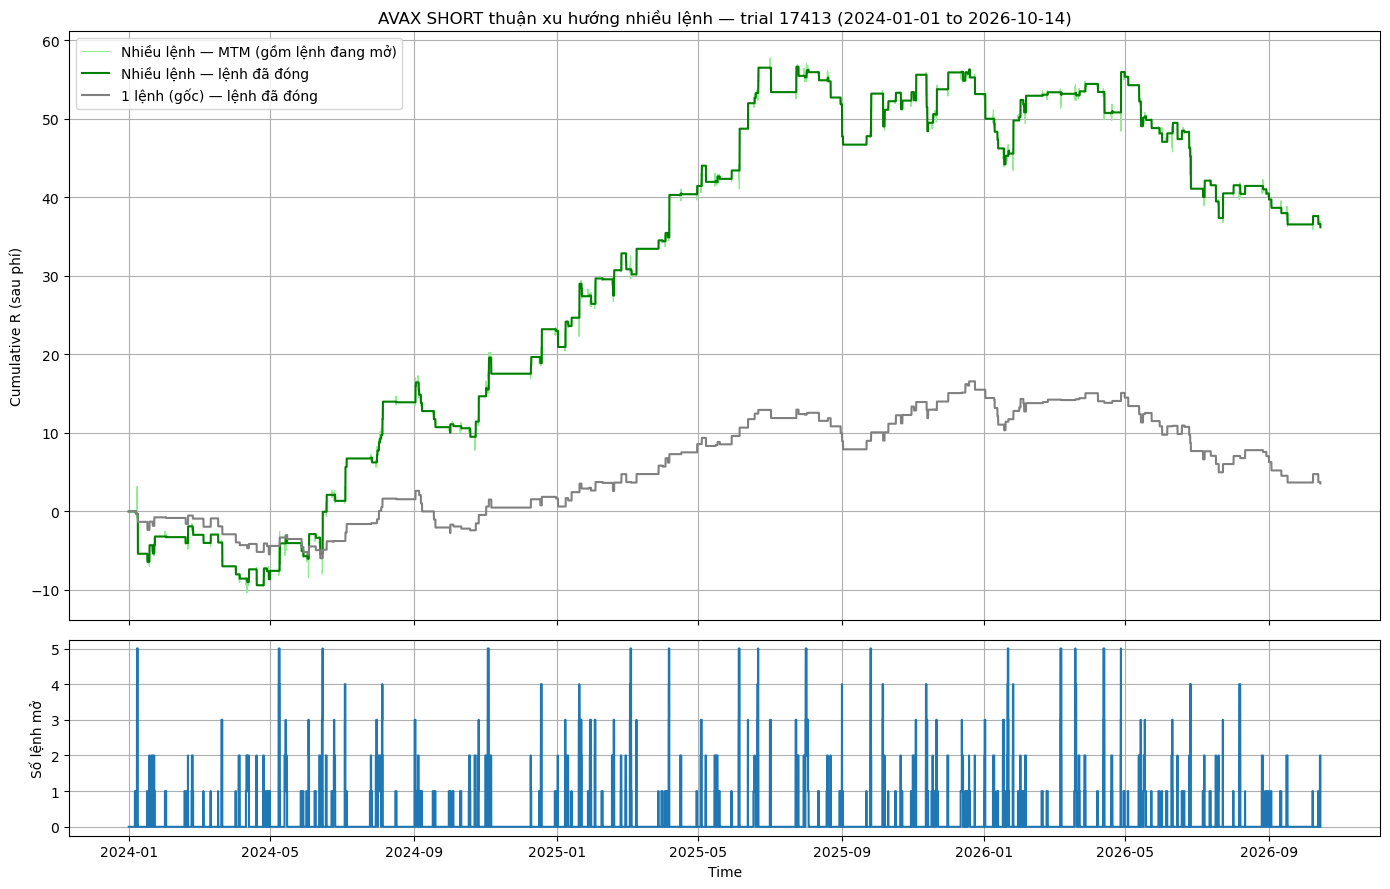

In [11]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này. None = bộ đứng đầu `ranked`.
TRIAL_ID = None  # Ví dụ 12354; None = bộ đứng đầu ranked
BACKTEST_START_DATE = "2024-01-01"  # Ví dụ "2025-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-10-14"    # Ví dụ "2026-01-14"; None = ngày kết thúc train

if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
params = grid.loc[TRIAL_ID].to_dict()
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))

# GPU cho đúng một bộ tham số, và replay float64 liệt kê từng lệnh; hai bên phải khớp.
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, grid.loc[[TRIAL_ID]].reset_index(drop=True), TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS, score_formula=SCORE_FORMULA, max_open=MAX_OPEN)
backtest_trial = backtest_result.iloc[0]
trades = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, MAX_OPEN)
replay = strategy.trade_metrics(backtest_bars, trades, TIMEFRAME, FEE_BARS)
if replay["number_of_trade"] != int(backtest_trial["number_of_trade"]):
    print(f"Lưu ý: GPU {int(backtest_trial['number_of_trade'])} lệnh, replay float64 {replay['number_of_trade']} "
          "(giá sát ngưỡng làm tròn fp32)")
single = strategy.cpu_trace(backtest_bars, params, TIMEFRAME, MAX_HOLDING_BARS, FEE_BARS, 1)
single_metrics = strategy.trade_metrics(backtest_bars, single, TIMEFRAME, FEE_BARS)

print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
print("Tham số:", params)
display(backtest_trial.to_frame(name="backtest_trial").T)
display(pd.DataFrame({f"nhiều lệnh (MAX_OPEN={MAX_OPEN})": replay, "1 lệnh (gốc)": single_metrics}).T)
display(trades["outcome"].value_counts().to_frame("số lệnh"))
display(trades.head(20))

if trades.empty:
    print("Không có lệnh nào trong khoảng backtest")
else:
    equity = strategy.mtm_equity(backtest_bars, trades, TIMEFRAME, FEE_BARS)
    single_equity = strategy.mtm_equity(backtest_bars, single, TIMEFRAME, FEE_BARS)
    fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    axes[0].plot(equity["timestamp"], equity["mtm_equity"], color="lightgreen", linewidth=0.8,
                 label="Nhiều lệnh — MTM (gồm lệnh đang mở)")
    axes[0].plot(equity["timestamp"], equity["closed_equity"], color="green", label="Nhiều lệnh — lệnh đã đóng")
    axes[0].plot(single_equity["timestamp"], single_equity["closed_equity"], color="gray",
                 label="1 lệnh (gốc) — lệnh đã đóng")
    axes[0].set(ylabel="Cumulative R (sau phí)",
                title=f"AVAX SHORT thuận xu hướng nhiều lệnh — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    axes[0].legend()
    axes[0].grid(True)
    axes[1].step(equity["timestamp"], equity["open_trades"], where="post", color="tab:blue")
    axes[1].set(xlabel="Time", ylabel="Số lệnh mở")
    axes[1].grid(True)
    fig.tight_layout()
    plt.show()

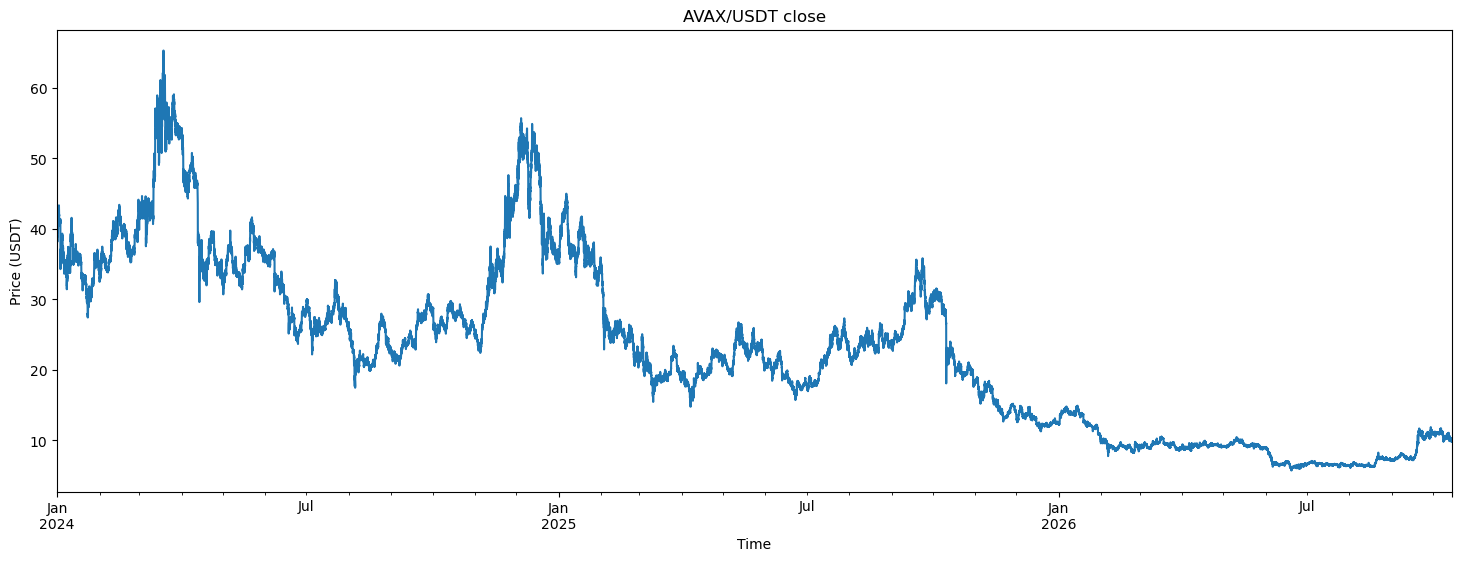

In [12]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()